In [1]:
1/6

0.16666666666666666

In [2]:
from __future__ import annotations

from typing import List, Tuple
import numpy as np
import qutip as qt


# ============================================================
# Local operators
# ============================================================

def op_on_site(op: qt.Qobj, N: int, site: int) -> qt.Qobj:
    if not (0 <= site < N):
        raise ValueError("site out of range")
    ops = [qt.qeye(2)] * N
    ops[site] = op
    return qt.tensor(ops)


def two_site_op(opA: qt.Qobj, opB: qt.Qobj, N: int, i: int, j: int) -> qt.Qobj:
    if i == j:
        raise ValueError("i and j must differ")
    ops = [qt.qeye(2)] * N
    ops[i] = opA
    ops[j] = opB
    return qt.tensor(ops)


# ============================================================
# Hamiltonian
# ============================================================

def kac_factor(N: int, alpha: float) -> float:
    r = np.arange(1, N, dtype=float)
    return np.sum((N - r) / (r ** alpha)) / (N - 1)


def build_H_B_Jz_Jlong(
    N: int,
    Bx: float,
    Jz: float,
    Jx: float,
    alpha: float,
    kac: bool = True,
) -> qt.Qobj:

    if N < 2:
        raise ValueError("N must be >= 2")

    sx, sz = qt.sigmax(), qt.sigmaz()
    H = 0

    # Kac normalization
    if kac:
        Jz = Jz / kac_factor(N, alpha)

    # field x
    for j in range(N):
        H += Bx * op_on_site(sx, N, j)

    # xx nearest neighbor
    for j in range(N - 1):
        H += Jx * two_site_op(sx, sx, N, j, j + 1)

    # zz long-range
    if alpha >= 100:
        for j in range(N - 1):
            H += Jz * two_site_op(sz, sz, N, j, j + 1)
    else:
        for i in range(N):
            for j in range(i + 1, N):
                r = j - i
                H += (Jz / (r ** alpha)) * two_site_op(sz, sz, N, i, j)

    return H


# ============================================================
# Diagonalization
# ============================================================

def diagonalize(H: qt.Qobj):
    evals, evecs = H.eigenstates()
    return np.array(evals), evecs


# ============================================================
# Product states
# ============================================================

def product_state_angles(thetas: np.ndarray, phis: np.ndarray) -> qt.Qobj:
    thetas = np.asarray(thetas)
    phis = np.asarray(phis)

    if thetas.shape != phis.shape:
        raise ValueError("shape mismatch")

    kets = [
        np.cos(t / 2) * qt.basis(2, 0)
        + np.exp(1j * p) * np.sin(t / 2) * qt.basis(2, 1)
        for t, p in zip(thetas, phis)
    ]

    return qt.tensor(kets).unit()


def product_state_x_pm(pm: str) -> qt.Qobj:
    pm = pm.strip()

    N = len(pm)
    thetas = np.full(N, np.pi / 2)
    phis = np.array([0 if c == "+" else np.pi for c in pm])

    return product_state_angles(thetas, phis)


def product_state_from_bitstring(bits: str) -> qt.Qobj:
    bits = bits.strip()

    kets = [qt.basis(2, int(b)) for b in bits]
    return qt.tensor(kets).unit()


# ============================================================
# Fidelity from spectrum
# ============================================================

def fidelity_from_spectrum(
    evals: np.ndarray,
    coeffs: np.ndarray,
    times: np.ndarray
) -> np.ndarray:

    weights = np.abs(coeffs) ** 2

    F = np.zeros(len(times))

    for k, t in enumerate(times):
        amp = np.sum(weights * np.exp(-1j * evals * t))
        F[k] = np.abs(amp) ** 2

    return F

# Collective Dephasing

In [5]:
import numpy as np
import qutip as qt
import matplotlib.pyplot as plt

N = 5
Jz = 10
Jx = 1.0
Bx = 1.0
gamma = 0.1

alphas = [0.1, 4, 1000]

tmax = 1000
times = np.linspace(0, tmax, 5000)

psi0 = product_state_from_bitstring("10" + "1"*(N-2))
rho0 = psi0 * psi0.dag()

F_dict = {}

for alpha in alphas:

    H = build_H_B_Jz_Jlong(N=N, Bx=Bx, Jz=Jz, Jx=Jx, alpha=alpha, kac=False)

    # collective DFS-compatible noise
    c_ops = [
        np.sqrt(gamma) * sum(op_on_site(qt.sigmaz(), N, i) for i in range(N))
    ]

    result = qt.mesolve(H, rho0, times, c_ops, [])
    rhos = result.states

    F_t = np.array([qt.expect(rho0, rho) for rho in rhos])

    F_dict[alpha] = F_t

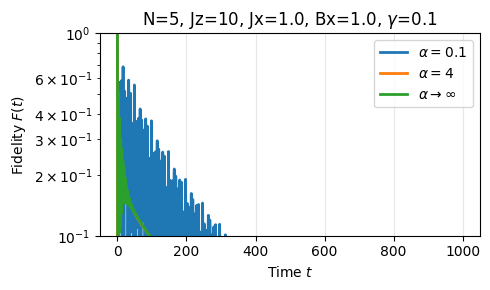

In [6]:
plt.figure(figsize=(5,3))

for alpha, F_t in F_dict.items():
    if alpha<100:
        label = fr"$\alpha={alpha}$"
    else:
        label = fr"$\alpha\to\infty$"
    plt.semilogy(times, F_t, lw=2, label=label)

plt.xlabel("Time $t$")
plt.ylim(1e-1,1)
plt.ylabel("Fidelity $F(t)$")
N = 5
Jz = 10
Jx = 1.0
Bx = 1.0
gamma = 0.1
plt.title(fr"N={N}, Jz={Jz}, Jx={Jx}, Bx={Bx}, $\gamma$={gamma}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("plt/dfs_fidelity_weak_strongdiss.pdf")
plt.show()

C:\Users\shrey\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\matplotlib\cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
C:\Users\shrey\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\matplotlib\cbook.py:1355: ComplexWarning: Casting complex values to real discards the imaginary part
  return np.asarray(x, float)


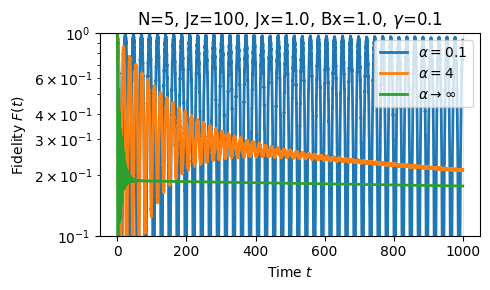

In [29]:
plt.figure(figsize=(5,3))

for alpha, F_t in F_dict.items():
    if alpha<100:
        label = fr"$\alpha={alpha}$"
    else:
        label = fr"$\alpha\to\infty$"
    plt.semilogy(times, F_t, lw=2, label=label)

plt.xlabel("Time $t$")
plt.ylim(1e-1,1)
plt.ylabel("Fidelity $F(t)$")
N = 5
Jz = 100
Jx = 1.0
Bx = 1.0
gamma = 0.1
plt.title(fr"N={N}, Jz={Jz}, Jx={Jx}, Bx={Bx}, $\gamma$={gamma}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("plt/dfs_fidelity_strong_diss.pdf")
plt.show()

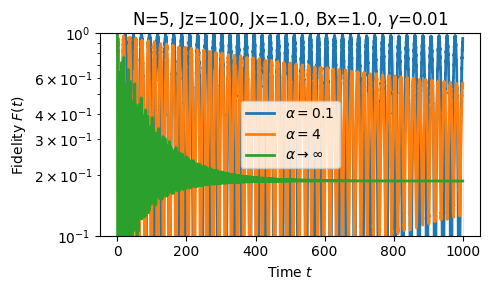

In [31]:
plt.figure(figsize=(5,3))

for alpha, F_t in F_dict.items():
    if alpha<100:
        label = fr"$\alpha={alpha}$"
    else:
        label = fr"$\alpha\to\infty$"
    plt.semilogy(times, F_t, lw=2, label=label)

plt.xlabel("Time $t$")
plt.ylim(1e-1,1)
plt.ylabel("Fidelity $F(t)$")
N = 5
Jz = 100
Jx = 1.0
Bx = 1.0
gamma = 0.01
plt.title(fr"N={N}, Jz={Jz}, Jx={Jx}, Bx={Bx}, $\gamma$={gamma}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("plt/dfs_fidelity.pdf")
plt.show()

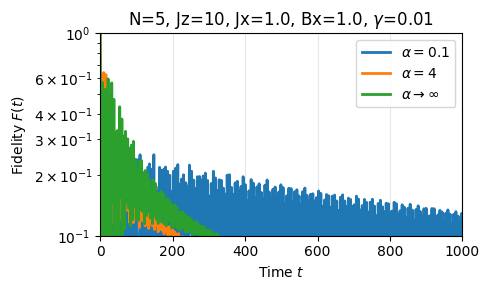

In [17]:
plt.figure(figsize=(5,3))

for alpha, F_t in F_dict.items():
    if alpha<100:
        label = fr"$\alpha={alpha}$"
    else:
        label = fr"$\alpha\to\infty$"
    plt.semilogy(times, F_t, lw=2, label=label)

plt.xlabel("Time $t$")
plt.xlim(0,1000)
plt.ylim(1e-1,1)
plt.ylabel("Fidelity $F(t)$")
N = 5
Jz = 10
Jx = 1.0
Bx = 1.0
gamma = 0.01
plt.title(fr"N={N}, Jz={Jz}, Jx={Jx}, Bx={Bx}, $\gamma$={gamma}")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("plt/dfs_fidelity_weak.pdf")
plt.show()

In [21]:

[i/5 for i in range(5)] + [1,2,4,6,8,10]

[0.0, 0.2, 0.4, 0.6, 0.8, 1, 2, 4, 6, 8, 10]

In [37]:
import numpy as np
import qutip as qt
import pandas as pd
import os

# =========================
# Parameters
# =========================

N = 5

Jz = 10
Jx = 1.0
Bx = 1.0

gammas = [0.0, 0.001, 0.01, 0.1] #

alphas = [i/5 for i in range(5)] + [1,2,4,6,8,10]

tmax = 100
times = np.linspace(0, tmax, 500)

# =========================
# Initial state
# =========================

psi0 = product_state_from_bitstring("10" + "1"*(N-2))
rho0 = psi0 * psi0.dag()

# =========================
# Save directory
# =========================

save_dir = "ED_Data/OpenMemory"
os.makedirs(save_dir, exist_ok=True)

# =========================
# Main loop
# =========================

for gamma in gammas:

    print(f"\nRunning gamma = {gamma}")

    for alpha in alphas:

        print(f"   alpha = {alpha}")

        # =========================
        # Hamiltonian
        # =========================

        H = build_H_B_Jz_Jlong(
            N=N,
            Bx=Bx,
            Jz=Jz,
            Jx=Jx,
            alpha=alpha,
            kac=False
        )

        # =========================
        # Collapse operators
        # =========================

        c_ops = [
            np.sqrt(gamma) *
            sum(
                op_on_site(qt.sigmaz(), N, i)
                for i in range(N)
            )
        ]

        # =========================
        # Time evolution
        # =========================

        result = qt.mesolve(
            H,
            rho0,
            times,
            c_ops,
            []
        )

        # =========================
        # Fidelity vs time
        # =========================

        F_t = np.array([
            qt.expect(rho0, rho)
            for rho in result.states
        ])

        # =========================
        # Save dataframe
        # =========================

        df = pd.DataFrame({
            "time": times,
            "fidelity": F_t
        })

        # =========================
        # Filename
        # =========================

        filename = (
            f"Fidelity_vs_time_"
            f"N{N}_"
            f"Jz{Jz}_"
            f"Jx{Jx}_"
            f"Bx{Bx}_"
            f"alpha{alpha}_"
            f"gamma{gamma}.csv"
        )

        save_path = os.path.join(save_dir, filename)

        # =========================
        # Save CSV
        # =========================

        df.to_csv(save_path, index=False)

        print(f"      saved -> {save_path}")


Running gamma = 0.0
   alpha = 0.0


C:\Users\shrey\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\qutip\solver\solver_base.py:598: FutureWarning: e_ops will be keyword only from qutip 5.3 for all solver
  warnings.warn(


      saved -> ED_Data/OpenMemory\Fidelity_vs_time_N5_Jz10_Jx1.0_Bx1.0_alpha0.0_gamma0.0.csv
   alpha = 0.2
      saved -> ED_Data/OpenMemory\Fidelity_vs_time_N5_Jz10_Jx1.0_Bx1.0_alpha0.2_gamma0.0.csv
   alpha = 0.4
      saved -> ED_Data/OpenMemory\Fidelity_vs_time_N5_Jz10_Jx1.0_Bx1.0_alpha0.4_gamma0.0.csv
   alpha = 0.6
      saved -> ED_Data/OpenMemory\Fidelity_vs_time_N5_Jz10_Jx1.0_Bx1.0_alpha0.6_gamma0.0.csv
   alpha = 0.8
      saved -> ED_Data/OpenMemory\Fidelity_vs_time_N5_Jz10_Jx1.0_Bx1.0_alpha0.8_gamma0.0.csv
   alpha = 1
      saved -> ED_Data/OpenMemory\Fidelity_vs_time_N5_Jz10_Jx1.0_Bx1.0_alpha1_gamma0.0.csv
   alpha = 2
      saved -> ED_Data/OpenMemory\Fidelity_vs_time_N5_Jz10_Jx1.0_Bx1.0_alpha2_gamma0.0.csv
   alpha = 4
      saved -> ED_Data/OpenMemory\Fidelity_vs_time_N5_Jz10_Jx1.0_Bx1.0_alpha4_gamma0.0.csv
   alpha = 6
      saved -> ED_Data/OpenMemory\Fidelity_vs_time_N5_Jz10_Jx1.0_Bx1.0_alpha6_gamma0.0.csv
   alpha = 8
      saved -> ED_Data/OpenMemory\Fidelity_vs_

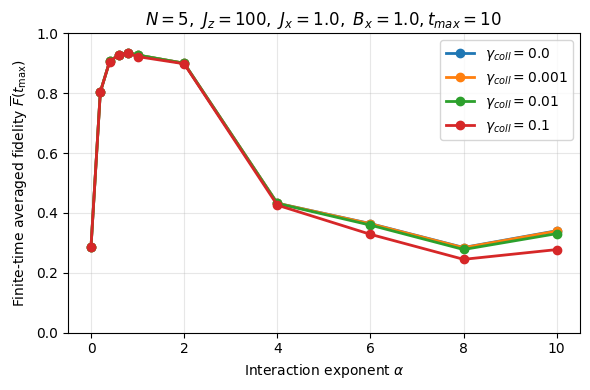

In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# Parameters
# =========================

N = 5

Jz = 100
Jx = 1.0
Bx = 1.0

gammas = [0.0, 0.001, 0.01, 0.1]

alphas = [i/5 for i in range(5)] + [1,2,4,6,8,10]

# finite time window for averaging
tmax_cut = 10  # choose < total simulation time

# =========================
# Storage
# =========================

Favg_dict = {}

# =========================
# Loop over gammas
# =========================

for gamma in gammas:

    Favg_list = []

    for alpha in alphas:

        filename = (
            f"ED_Data/OpenMemory/"
            f"Fidelity_vs_time_"
            f"N{N}_"
            f"Jz{Jz}_"
            f"Jx{Jx}_"
            f"Bx{Bx}_"
            f"alpha{alpha}_"
            f"gamma{gamma}.csv"
        )

        # =========================
        # Load data
        # =========================

        df = pd.read_csv(filename)

        times = df["time"].to_numpy(dtype=float)

        # convert "(1+0j)" strings safely -> real float
        F_t = df["fidelity"].apply(lambda x: np.real(complex(x))).to_numpy()

        # =========================
        # Finite-time averaging
        # =========================

        mask = times <= tmax_cut

        F_avg = np.trapezoid(
            F_t[mask],
            times[mask]
        ) / tmax_cut

        Favg_list.append(F_avg)

    Favg_dict[gamma] = np.array(Favg_list)

# =========================
# Plot
# =========================

plt.figure(figsize=(6,4))

for gamma in gammas:

    plt.plot(
        alphas,
        Favg_dict[gamma],
        marker='o',
        lw=2,
        label=fr"$\gamma_{{coll}}={gamma}$"
    )

plt.xlabel(r"Interaction exponent $\alpha$")
plt.ylabel(r"Finite-time averaged fidelity $\overline{F}(t_{\max})$")
plt.ylim(0,1)
plt.title(fr"$N={N},\ J_z={Jz},\ J_x={Jx},\ B_x={Bx}, t_{{max}}={tmax_cut}$")

plt.grid(alpha=0.3)

plt.legend()

plt.tight_layout()

plt.savefig("plt/CollectiveDephasing_fidelity_vs_alpha.pdf")

plt.show()

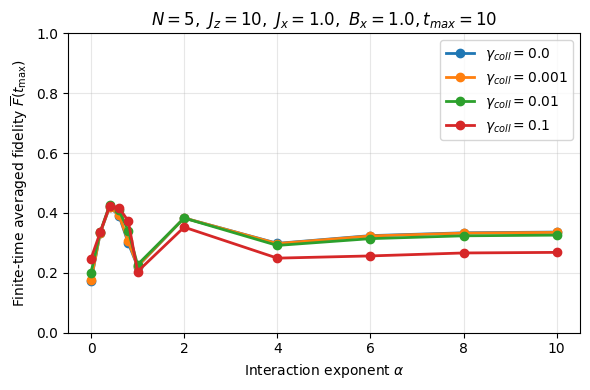

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =========================
# Parameters
# =========================

N = 5

Jz = 10
Jx = 1.0
Bx = 1.0

gammas = [0.0, 0.001, 0.01, 0.1]

alphas = [i/5 for i in range(5)] + [1,2,4,6,8,10]

# finite time window for averaging
tmax_cut = 10  # choose < total simulation time

# =========================
# Storage
# =========================

Favg_dict = {}

# =========================
# Loop over gammas
# =========================

for gamma in gammas:

    Favg_list = []

    for alpha in alphas:

        filename = (
            f"ED_Data/OpenMemory/"
            f"Fidelity_vs_time_"
            f"N{N}_"
            f"Jz{Jz}_"
            f"Jx{Jx}_"
            f"Bx{Bx}_"
            f"alpha{alpha}_"
            f"gamma{gamma}.csv"
        )

        # =========================
        # Load data
        # =========================

        df = pd.read_csv(filename)

        times = df["time"].to_numpy(dtype=float)

        # convert "(1+0j)" strings safely -> real float
        F_t = df["fidelity"].apply(lambda x: np.real(complex(x))).to_numpy()

        # =========================
        # Finite-time averaging
        # =========================

        mask = times <= tmax_cut

        F_avg = np.trapezoid(
            F_t[mask],
            times[mask]
        ) / tmax_cut

        Favg_list.append(F_avg)

    Favg_dict[gamma] = np.array(Favg_list)

# =========================
# Plot
# =========================

plt.figure(figsize=(6,4))

for gamma in gammas:

    plt.plot(
        alphas,
        Favg_dict[gamma],
        marker='o',
        lw=2,
        label=fr"$\gamma_{{coll}}={gamma}$"
    )

plt.xlabel(r"Interaction exponent $\alpha$")
plt.ylabel(r"Finite-time averaged fidelity $\overline{F}(t_{\max})$")
plt.ylim(0,1)

plt.title(fr"$N={N},\ J_z={Jz},\ J_x={Jx},\ B_x={Bx}, t_{{max}}={tmax_cut}$")

plt.grid(alpha=0.3)

plt.legend()

plt.tight_layout()

plt.savefig("plt/CollectiveDephasing_fidelity_vs_alpha_Jz10.pdf")

plt.show()

# Collective Dephasing

In [19]:
import numpy as np
import qutip as qt
import pandas as pd
import os

# =========================
# Parameters
# =========================

N = 5

Jz = 1
Jx = 1.0
Bx = 1.0

gammas = [0.0, 0.001, 0.01, 0.1] #

alphas = [i/5 for i in range(5)] + [1,2,4,6,8,10]

tmax = 100
times = np.linspace(0, tmax, 500)

i0 = 2  # site of interest

# =========================
# Initial state
# =========================

psi0 = product_state_from_bitstring("10" + "1"*(N-2))
rho0 = psi0 * psi0.dag()

# =========================
# Save directory
# =========================

save_dir = "ED_Data/OpenMemory/CollectiveDephasing"
os.makedirs(save_dir, exist_ok=True)

# =========================
# Main loop
# =========================

for gamma in gammas:

    print(f"\nRunning gamma = {gamma}")

    for alpha in alphas:

        print(f"   alpha = {alpha}")

        # =========================
        # Hamiltonian
        # =========================

        H = build_H_B_Jz_Jlong(
            N=N,
            Bx=Bx,
            Jz=Jz,
            Jx=Jx,
            alpha=alpha,
            kac=False
        )

        # =========================
        # Collective dephasing
        # =========================

        c_ops = [
            np.sqrt(gamma) *
            sum(
                op_on_site(qt.sigmaz(), N, i)
                for i in range(N)
            )
        ]
        # =========================
        # Time evolution
        # =========================

        result = qt.mesolve(
            H,
            rho0,
            times,
            c_ops,
            []
        )

        # =========================
        # Reduced density matrix at site i0
        # =========================

        rho_i0_t = []

        for rho in result.states:

            rho_i0 = qt.ptrace(rho, i0)

            # store as flattened real/imag components
            rho_i0_t.append([
                rho_i0[0,0].real,
                rho_i0[1,1].real,
                rho_i0[0,1].real,
                rho_i0[0,1].imag
            ])

        rho_i0_t = np.array(rho_i0_t)

        # =========================
        # Save dataframe
        # =========================

        df = pd.DataFrame({
            "time": times,
            "rho_00": rho_i0_t[:,0],
            "rho_11": rho_i0_t[:,1],
            "rho_01_real": rho_i0_t[:,2],
            "rho_01_imag": rho_i0_t[:,3],
        })

        # =========================
        # Filename
        # =========================

        filename = (
            f"RDM_site{i0}_vs_time_"
            f"N{N}_"
            f"Jz{Jz}_"
            f"Jx{Jx}_"
            f"Bx{Bx}_"
            f"alpha{alpha}_"
            f"gamma{gamma}.csv"
        )

        save_path = os.path.join(save_dir, filename)

        df.to_csv(save_path, index=False)

        print(f"      saved -> {save_path}")


Running gamma = 0.0
   alpha = 0.0


C:\Users\shrey\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\qutip\solver\solver_base.py:598: FutureWarning: e_ops will be keyword only from qutip 5.3 for all solver
  warnings.warn(


      saved -> ED_Data/OpenMemory/CollectiveDephasing\RDM_site2_vs_time_N5_Jz1_Jx1.0_Bx1.0_alpha0.0_gamma0.0.csv
   alpha = 0.2
      saved -> ED_Data/OpenMemory/CollectiveDephasing\RDM_site2_vs_time_N5_Jz1_Jx1.0_Bx1.0_alpha0.2_gamma0.0.csv
   alpha = 0.4
      saved -> ED_Data/OpenMemory/CollectiveDephasing\RDM_site2_vs_time_N5_Jz1_Jx1.0_Bx1.0_alpha0.4_gamma0.0.csv
   alpha = 0.6
      saved -> ED_Data/OpenMemory/CollectiveDephasing\RDM_site2_vs_time_N5_Jz1_Jx1.0_Bx1.0_alpha0.6_gamma0.0.csv
   alpha = 0.8
      saved -> ED_Data/OpenMemory/CollectiveDephasing\RDM_site2_vs_time_N5_Jz1_Jx1.0_Bx1.0_alpha0.8_gamma0.0.csv
   alpha = 1
      saved -> ED_Data/OpenMemory/CollectiveDephasing\RDM_site2_vs_time_N5_Jz1_Jx1.0_Bx1.0_alpha1_gamma0.0.csv
   alpha = 2
      saved -> ED_Data/OpenMemory/CollectiveDephasing\RDM_site2_vs_time_N5_Jz1_Jx1.0_Bx1.0_alpha2_gamma0.0.csv
   alpha = 4
      saved -> ED_Data/OpenMemory/CollectiveDephasing\RDM_site2_vs_time_N5_Jz1_Jx1.0_Bx1.0_alpha4_gamma0.0.csv
   

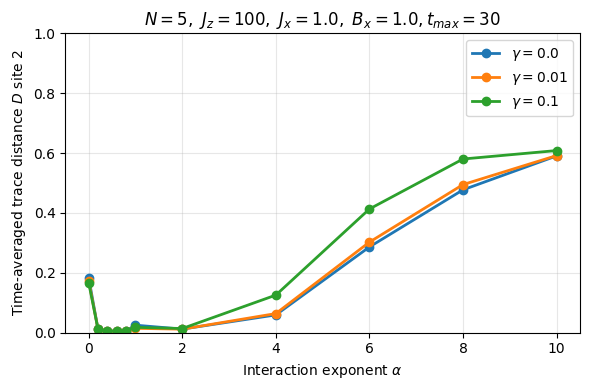

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import qutip as qt

# =========================
# Parameters
# =========================

N = 5
Jz = 100
Jx = 1.0
Bx = 1.0

gammas = [0.0, 0.01, 0.1] #
alphas = [i/5 for i in range(5)] + [1,2,4,6,8,10]

i0 = 2
tmax_cut = 30   # choose your physical observation window

plt.figure(figsize=(6,4))

# =========================
# Loop over gammas
# =========================

for gamma in gammas:

    D_avg_list = []

    for alpha in alphas:

        filename = (
            f"ED_Data/OpenMemory/CollectiveDephasing/"
            f"RDM_site{i0}_vs_time_"
            f"N{N}_Jz{Jz}_Jx{Jx}_Bx{Bx}_"
            f"alpha{alpha}_gamma{gamma}.csv"
        )

        df = pd.read_csv(filename)

        # =========================
        # Reconstruct rho(t)
        # =========================

        times = df["time"].to_numpy()

        rho0 = qt.Qobj([
            [df["rho_00"].iloc[0], 
             df["rho_01_real"].iloc[0] + 1j*df["rho_01_imag"].iloc[0]],
            [df["rho_01_real"].iloc[0] - 1j*df["rho_01_imag"].iloc[0],
             df["rho_11"].iloc[0]]
        ])

        D_t = []

        for i in range(len(df)):

            rho_t = qt.Qobj([
                [df["rho_00"].iloc[i],
                 df["rho_01_real"].iloc[i] + 1j*df["rho_01_imag"].iloc[i]],
                [df["rho_01_real"].iloc[i] - 1j*df["rho_01_imag"].iloc[i],
                 df["rho_11"].iloc[i]]
            ])

            D_t.append(qt.tracedist(rho_t, rho0))

        D_t = np.array(D_t)

        # =========================
        # Time average
        # =========================

        

        mask = times <= tmax_cut

        D_avg = np.trapezoid(D_t[mask], times[mask]) / tmax_cut
        D_avg_list.append(D_avg)

    plt.plot(alphas, D_avg_list, marker='o', lw=2, label=fr"$\gamma={gamma}$")

# =========================
# Plot styling
# =========================

plt.xlabel(r"Interaction exponent $\alpha$")
plt.ylabel(rf"Time-averaged trace distance $D$ site {i0}")
plt.ylim(0,1)
plt.title(fr"Local decoherence at ")
plt.title(fr"$N={N},\ J_z={Jz},\ J_x={Jx},\ B_x={Bx}, t_{{max}}={tmax_cut}$")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.savefig("plt/CollectiveDephasing_tracedist_vs_alpha_Jz100.pdf")
plt.show()

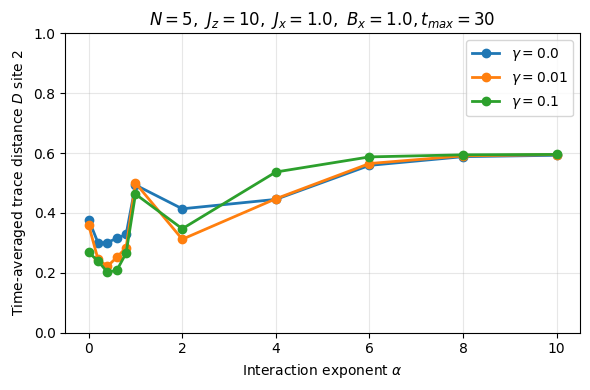

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import qutip as qt

# =========================
# Parameters
# =========================

N = 5
Jz = 10
Jx = 1.0
Bx = 1.0

gammas = [0.0, 0.01, 0.1] #
alphas = [i/5 for i in range(5)] + [1,2,4,6,8,10]

i0 = 2
tmax_cut = 30   # choose your physical observation window

plt.figure(figsize=(6,4))

# =========================
# Loop over gammas
# =========================

for gamma in gammas:

    D_avg_list = []

    for alpha in alphas:

        filename = (
            f"ED_Data/OpenMemory/CollectiveDephasing/"
            f"RDM_site{i0}_vs_time_"
            f"N{N}_Jz{Jz}_Jx{Jx}_Bx{Bx}_"
            f"alpha{alpha}_gamma{gamma}.csv"
        )

        df = pd.read_csv(filename)

        # =========================
        # Reconstruct rho(t)
        # =========================

        times = df["time"].to_numpy()

        rho0 = qt.Qobj([
            [df["rho_00"].iloc[0], 
             df["rho_01_real"].iloc[0] + 1j*df["rho_01_imag"].iloc[0]],
            [df["rho_01_real"].iloc[0] - 1j*df["rho_01_imag"].iloc[0],
             df["rho_11"].iloc[0]]
        ])

        D_t = []

        for i in range(len(df)):

            rho_t = qt.Qobj([
                [df["rho_00"].iloc[i],
                 df["rho_01_real"].iloc[i] + 1j*df["rho_01_imag"].iloc[i]],
                [df["rho_01_real"].iloc[i] - 1j*df["rho_01_imag"].iloc[i],
                 df["rho_11"].iloc[i]]
            ])

            D_t.append(qt.tracedist(rho_t, rho0))

        D_t = np.array(D_t)

        # =========================
        # Time average
        # =========================

        

        mask = times <= tmax_cut

        D_avg = np.trapezoid(D_t[mask], times[mask]) / tmax_cut
        D_avg_list.append(D_avg)

    plt.plot(alphas, D_avg_list, marker='o', lw=2, label=fr"$\gamma={gamma}$")

# =========================
# Plot styling
# =========================

plt.xlabel(r"Interaction exponent $\alpha$")
plt.ylabel(rf"Time-averaged trace distance $D$ site {i0}")
plt.ylim(0,1)
plt.title(fr"Local decoherence at ")
plt.title(fr"$N={N},\ J_z={Jz},\ J_x={Jx},\ B_x={Bx}, t_{{max}}={tmax_cut}$")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.savefig("plt/CollectiveDephasing_tracedist_vs_alpha_Jz10.pdf")
plt.show()

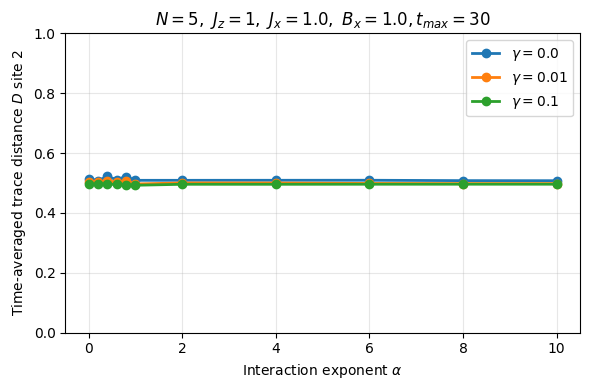

In [21]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import qutip as qt

# =========================
# Parameters
# =========================

N = 5
Jz = 1
Jx = 1.0
Bx = 1.0

gammas = [0.0, 0.01, 0.1] #
alphas = [i/5 for i in range(5)] + [1,2,4,6,8,10]

i0 = 2
tmax_cut = 30   # choose your physical observation window

plt.figure(figsize=(6,4))

# =========================
# Loop over gammas
# =========================

for gamma in gammas:

    D_avg_list = []

    for alpha in alphas:

        filename = (
            f"ED_Data/OpenMemory/CollectiveDephasing/"
            f"RDM_site{i0}_vs_time_"
            f"N{N}_Jz{Jz}_Jx{Jx}_Bx{Bx}_"
            f"alpha{alpha}_gamma{gamma}.csv"
        )

        df = pd.read_csv(filename)

        # =========================
        # Reconstruct rho(t)
        # =========================

        times = df["time"].to_numpy()

        rho0 = qt.Qobj([
            [df["rho_00"].iloc[0], 
             df["rho_01_real"].iloc[0] + 1j*df["rho_01_imag"].iloc[0]],
            [df["rho_01_real"].iloc[0] - 1j*df["rho_01_imag"].iloc[0],
             df["rho_11"].iloc[0]]
        ])

        D_t = []

        for i in range(len(df)):

            rho_t = qt.Qobj([
                [df["rho_00"].iloc[i],
                 df["rho_01_real"].iloc[i] + 1j*df["rho_01_imag"].iloc[i]],
                [df["rho_01_real"].iloc[i] - 1j*df["rho_01_imag"].iloc[i],
                 df["rho_11"].iloc[i]]
            ])

            D_t.append(qt.tracedist(rho_t, rho0))

        D_t = np.array(D_t)

        # =========================
        # Time average
        # =========================

        

        mask = times <= tmax_cut

        D_avg = np.trapezoid(D_t[mask], times[mask]) / tmax_cut
        D_avg_list.append(D_avg)

    plt.plot(alphas, D_avg_list, marker='o', lw=2, label=fr"$\gamma={gamma}$")

# =========================
# Plot styling
# =========================

plt.xlabel(r"Interaction exponent $\alpha$")
plt.ylabel(rf"Time-averaged trace distance $D$ site {i0}")
plt.ylim(0,1)
plt.title(fr"Local decoherence at ")
plt.title(fr"$N={N},\ J_z={Jz},\ J_x={Jx},\ B_x={Bx}, t_{{max}}={tmax_cut}$")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.savefig("plt/CollectiveDephasing_tracedist_vs_alpha_Jz1.pdf")
plt.show()

# Local Dephasing

In [70]:
import numpy as np
import qutip as qt
import pandas as pd
import os

# =========================
# Parameters
# =========================

N = 5

Jz = 1
Jx = 1.0
Bx = 1.0

gammas = [0.0, 0.001, 0.01, 0.1] #

alphas = [i/5 for i in range(5)] + [1,2,4,6,8,10]

tmax = 100
times = np.linspace(0, tmax, 500)

i0 = 2  # site of interest

# =========================
# Initial state
# =========================

psi0 = product_state_from_bitstring("10" + "1"*(N-2))
rho0 = psi0 * psi0.dag()

# =========================
# Save directory
# =========================

save_dir = "ED_Data/OpenMemory/LocalDephasing"
os.makedirs(save_dir, exist_ok=True)

# =========================
# Main loop
# =========================

for gamma in gammas:

    print(f"\nRunning gamma = {gamma}")

    for alpha in alphas:

        print(f"   alpha = {alpha}")

        # =========================
        # Hamiltonian
        # =========================

        H = build_H_B_Jz_Jlong(
            N=N,
            Bx=Bx,
            Jz=Jz,
            Jx=Jx,
            alpha=alpha,
            kac=False
        )

        # =========================
        # LOCAL dephasing (NOT collective)
        # =========================

        c_ops = [
            np.sqrt(gamma) * op_on_site(qt.sigmaz(), N, i)
            for i in range(N)
        ]

        # =========================
        # Time evolution
        # =========================

        result = qt.mesolve(
            H,
            rho0,
            times,
            c_ops,
            []
        )

        # =========================
        # Reduced density matrix at site i0
        # =========================

        rho_i0_t = []

        for rho in result.states:

            rho_i0 = qt.ptrace(rho, i0)

            # store as flattened real/imag components
            rho_i0_t.append([
                rho_i0[0,0].real,
                rho_i0[1,1].real,
                rho_i0[0,1].real,
                rho_i0[0,1].imag
            ])

        rho_i0_t = np.array(rho_i0_t)

        # =========================
        # Save dataframe
        # =========================

        df = pd.DataFrame({
            "time": times,
            "rho_00": rho_i0_t[:,0],
            "rho_11": rho_i0_t[:,1],
            "rho_01_real": rho_i0_t[:,2],
            "rho_01_imag": rho_i0_t[:,3],
        })

        # =========================
        # Filename
        # =========================

        filename = (
            f"RDM_site{i0}_vs_time_"
            f"N{N}_"
            f"Jz{Jz}_"
            f"Jx{Jx}_"
            f"Bx{Bx}_"
            f"alpha{alpha}_"
            f"gamma{gamma}.csv"
        )

        save_path = os.path.join(save_dir, filename)

        df.to_csv(save_path, index=False)

        print(f"      saved -> {save_path}")


Running gamma = 0.0
   alpha = 0.0


C:\Users\shrey\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\qutip\solver\solver_base.py:598: FutureWarning: e_ops will be keyword only from qutip 5.3 for all solver
  warnings.warn(


      saved -> ED_Data/OpenMemory/LocalDephasing\RDM_site2_vs_time_N5_Jz1_Jx1.0_Bx1.0_alpha0.0_gamma0.0.csv
   alpha = 0.2
      saved -> ED_Data/OpenMemory/LocalDephasing\RDM_site2_vs_time_N5_Jz1_Jx1.0_Bx1.0_alpha0.2_gamma0.0.csv
   alpha = 0.4
      saved -> ED_Data/OpenMemory/LocalDephasing\RDM_site2_vs_time_N5_Jz1_Jx1.0_Bx1.0_alpha0.4_gamma0.0.csv
   alpha = 0.6
      saved -> ED_Data/OpenMemory/LocalDephasing\RDM_site2_vs_time_N5_Jz1_Jx1.0_Bx1.0_alpha0.6_gamma0.0.csv
   alpha = 0.8
      saved -> ED_Data/OpenMemory/LocalDephasing\RDM_site2_vs_time_N5_Jz1_Jx1.0_Bx1.0_alpha0.8_gamma0.0.csv
   alpha = 1
      saved -> ED_Data/OpenMemory/LocalDephasing\RDM_site2_vs_time_N5_Jz1_Jx1.0_Bx1.0_alpha1_gamma0.0.csv
   alpha = 2
      saved -> ED_Data/OpenMemory/LocalDephasing\RDM_site2_vs_time_N5_Jz1_Jx1.0_Bx1.0_alpha2_gamma0.0.csv
   alpha = 4
      saved -> ED_Data/OpenMemory/LocalDephasing\RDM_site2_vs_time_N5_Jz1_Jx1.0_Bx1.0_alpha4_gamma0.0.csv
   alpha = 6
      saved -> ED_Data/OpenMem

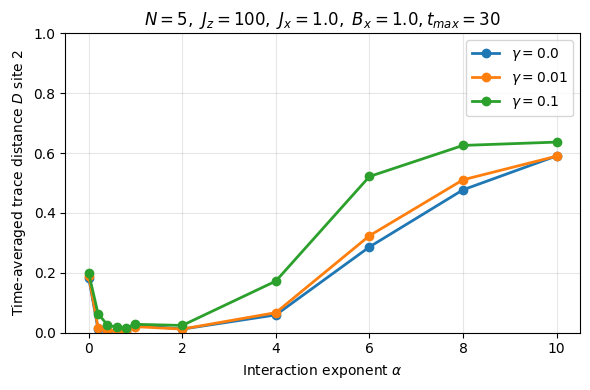

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import qutip as qt

# =========================
# Parameters
# =========================

N = 5
Jz = 100
Jx = 1.0
Bx = 1.0

gammas = [0.0, 0.01, 0.1] #
alphas = [i/5 for i in range(5)] + [1,2,4,6,8,10]

i0 = 2
tmax_cut = 30   # choose your physical observation window

plt.figure(figsize=(6,4))

# =========================
# Loop over gammas
# =========================

for gamma in gammas:

    D_avg_list = []

    for alpha in alphas:

        filename = (
            f"ED_Data/OpenMemory/LocalDephasing/"
            f"RDM_site{i0}_vs_time_"
            f"N{N}_Jz{Jz}_Jx{Jx}_Bx{Bx}_"
            f"alpha{alpha}_gamma{gamma}.csv"
        )

        df = pd.read_csv(filename)

        # =========================
        # Reconstruct rho(t)
        # =========================

        times = df["time"].to_numpy()

        rho0 = qt.Qobj([
            [df["rho_00"].iloc[0], 
             df["rho_01_real"].iloc[0] + 1j*df["rho_01_imag"].iloc[0]],
            [df["rho_01_real"].iloc[0] - 1j*df["rho_01_imag"].iloc[0],
             df["rho_11"].iloc[0]]
        ])

        D_t = []

        for i in range(len(df)):

            rho_t = qt.Qobj([
                [df["rho_00"].iloc[i],
                 df["rho_01_real"].iloc[i] + 1j*df["rho_01_imag"].iloc[i]],
                [df["rho_01_real"].iloc[i] - 1j*df["rho_01_imag"].iloc[i],
                 df["rho_11"].iloc[i]]
            ])

            D_t.append(qt.tracedist(rho_t, rho0))

        D_t = np.array(D_t)

        # =========================
        # Time average
        # =========================

        

        mask = times <= tmax_cut

        D_avg = np.trapezoid(D_t[mask], times[mask]) / tmax_cut
        D_avg_list.append(D_avg)

    plt.plot(alphas, D_avg_list, marker='o', lw=2, label=fr"$\gamma={gamma}$")

# =========================
# Plot styling
# =========================

plt.xlabel(r"Interaction exponent $\alpha$")
plt.ylabel(rf"Time-averaged trace distance $D$ site {i0}")
plt.ylim(0,1)
plt.title(fr"Local decoherence at ")
plt.title(fr"$N={N},\ J_z={Jz},\ J_x={Jx},\ B_x={Bx}, t_{{max}}={tmax_cut}$")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.savefig("plt/LocalDephasing_tracedist_vs_alpha_Jz100.pdf")
plt.show()

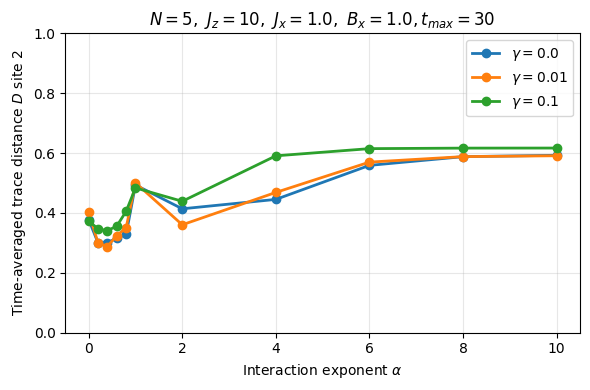

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import qutip as qt

# =========================
# Parameters
# =========================

N = 5
Jz = 10
Jx = 1.0
Bx = 1.0

gammas = [0.0, 0.01, 0.1] #
alphas = [i/5 for i in range(5)] + [1,2,4,6,8,10]

i0 = 2
tmax_cut = 30   # choose your physical observation window

plt.figure(figsize=(6,4))

# =========================
# Loop over gammas
# =========================

for gamma in gammas:

    D_avg_list = []

    for alpha in alphas:

        filename = (
            f"ED_Data/OpenMemory/LocalDephasing/"
            f"RDM_site{i0}_vs_time_"
            f"N{N}_Jz{Jz}_Jx{Jx}_Bx{Bx}_"
            f"alpha{alpha}_gamma{gamma}.csv"
        )

        df = pd.read_csv(filename)

        # =========================
        # Reconstruct rho(t)
        # =========================

        times = df["time"].to_numpy()

        rho0 = qt.Qobj([
            [df["rho_00"].iloc[0], 
             df["rho_01_real"].iloc[0] + 1j*df["rho_01_imag"].iloc[0]],
            [df["rho_01_real"].iloc[0] - 1j*df["rho_01_imag"].iloc[0],
             df["rho_11"].iloc[0]]
        ])

        D_t = []

        for i in range(len(df)):

            rho_t = qt.Qobj([
                [df["rho_00"].iloc[i],
                 df["rho_01_real"].iloc[i] + 1j*df["rho_01_imag"].iloc[i]],
                [df["rho_01_real"].iloc[i] - 1j*df["rho_01_imag"].iloc[i],
                 df["rho_11"].iloc[i]]
            ])

            D_t.append(qt.tracedist(rho_t, rho0))

        D_t = np.array(D_t)

        # =========================
        # Time average
        # =========================

        

        mask = times <= tmax_cut

        D_avg = np.trapezoid(D_t[mask], times[mask]) / tmax_cut
        D_avg_list.append(D_avg)

    plt.plot(alphas, D_avg_list, marker='o', lw=2, label=fr"$\gamma={gamma}$")

# =========================
# Plot styling
# =========================

plt.xlabel(r"Interaction exponent $\alpha$")
plt.ylabel(rf"Time-averaged trace distance $D$ site {i0}")
plt.ylim(0,1)
plt.title(fr"Local decoherence at ")
plt.title(fr"$N={N},\ J_z={Jz},\ J_x={Jx},\ B_x={Bx}, t_{{max}}={tmax_cut}$")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.savefig("plt/LocalDephasing_tracedist_vs_alpha_Jz10.pdf")
plt.show()

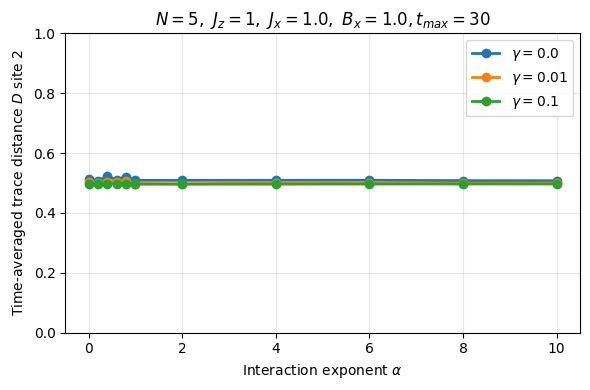

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import qutip as qt

# =========================
# Parameters
# =========================

N = 5
Jz = 1
Jx = 1.0
Bx = 1.0

gammas = [0.0, 0.01, 0.1] #
alphas = [i/5 for i in range(5)] + [1,2,4,6,8,10]

i0 = 2
tmax_cut = 30   # choose your physical observation window

plt.figure(figsize=(6,4))

# =========================
# Loop over gammas
# =========================

for gamma in gammas:

    D_avg_list = []

    for alpha in alphas:

        filename = (
            f"ED_Data/OpenMemory/LocalDephasing/"
            f"RDM_site{i0}_vs_time_"
            f"N{N}_Jz{Jz}_Jx{Jx}_Bx{Bx}_"
            f"alpha{alpha}_gamma{gamma}.csv"
        )

        df = pd.read_csv(filename)

        # =========================
        # Reconstruct rho(t)
        # =========================

        times = df["time"].to_numpy()

        rho0 = qt.Qobj([
            [df["rho_00"].iloc[0], 
             df["rho_01_real"].iloc[0] + 1j*df["rho_01_imag"].iloc[0]],
            [df["rho_01_real"].iloc[0] - 1j*df["rho_01_imag"].iloc[0],
             df["rho_11"].iloc[0]]
        ])

        D_t = []

        for i in range(len(df)):

            rho_t = qt.Qobj([
                [df["rho_00"].iloc[i],
                 df["rho_01_real"].iloc[i] + 1j*df["rho_01_imag"].iloc[i]],
                [df["rho_01_real"].iloc[i] - 1j*df["rho_01_imag"].iloc[i],
                 df["rho_11"].iloc[i]]
            ])

            D_t.append(qt.tracedist(rho_t, rho0))

        D_t = np.array(D_t)

        # =========================
        # Time average
        # =========================

        

        mask = times <= tmax_cut

        D_avg = np.trapezoid(D_t[mask], times[mask]) / tmax_cut
        D_avg_list.append(D_avg)

    plt.plot(alphas, D_avg_list, marker='o', lw=2, label=fr"$\gamma={gamma}$")

# =========================
# Plot styling
# =========================

plt.xlabel(r"Interaction exponent $\alpha$")
plt.ylabel(rf"Time-averaged trace distance $D$ site {i0}")
plt.ylim(0,1)
plt.title(fr"Local decoherence at ")
plt.title(fr"$N={N},\ J_z={Jz},\ J_x={Jx},\ B_x={Bx}, t_{{max}}={tmax_cut}$")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.savefig("plt/LocalDephasing_tracedist_vs_alpha_Jz1.pdf")
plt.show()

# Local bit flip X

In [12]:
import numpy as np
import qutip as qt
import pandas as pd
import os

# =========================
# Parameters
# =========================

N = 5

Jz = 1
Jx = 1.0
Bx = 1.0

gammas = [0.0, 0.001, 0.01, 0.1] #

alphas = [i/5 for i in range(5)] + [1,2,4,6,8,10]

tmax = 100
times = np.linspace(0, tmax, 500)

i0 = 2  # site of interest

# =========================
# Initial state
# =========================

psi0 = product_state_from_bitstring("10" + "1"*(N-2))
rho0 = psi0 * psi0.dag()

# =========================
# Save directory
# =========================

save_dir = "ED_Data/OpenMemory/LocalBitFlip"
os.makedirs(save_dir, exist_ok=True)

# =========================
# Main loop
# =========================

for gamma in gammas:

    print(f"\nRunning gamma = {gamma}")

    for alpha in alphas:

        print(f"   alpha = {alpha}")

        # =========================
        # Hamiltonian
        # =========================

        H = build_H_B_Jz_Jlong(
            N=N,
            Bx=Bx,
            Jz=Jz,
            Jx=Jx,
            alpha=alpha,
            kac=False
        )

        # =========================
        # LOCAL bit flip (NOT collective)
        # =========================

        c_ops = [
            np.sqrt(gamma) * op_on_site(qt.sigmax(), N, i)
            for i in range(N)
        ]

        # =========================
        # Time evolution
        # =========================

        result = qt.mesolve(
            H,
            rho0,
            times,
            c_ops,
            []
        )

        # =========================
        # Reduced density matrix at site i0
        # =========================

        rho_i0_t = []

        for rho in result.states:

            rho_i0 = qt.ptrace(rho, i0)

            # store as flattened real/imag components
            rho_i0_t.append([
                rho_i0[0,0].real,
                rho_i0[1,1].real,
                rho_i0[0,1].real,
                rho_i0[0,1].imag
            ])

        rho_i0_t = np.array(rho_i0_t)

        # =========================
        # Save dataframe
        # =========================

        df = pd.DataFrame({
            "time": times,
            "rho_00": rho_i0_t[:,0],
            "rho_11": rho_i0_t[:,1],
            "rho_01_real": rho_i0_t[:,2],
            "rho_01_imag": rho_i0_t[:,3],
        })

        # =========================
        # Filename
        # =========================

        filename = (
            f"RDM_site{i0}_vs_time_"
            f"N{N}_"
            f"Jz{Jz}_"
            f"Jx{Jx}_"
            f"Bx{Bx}_"
            f"alpha{alpha}_"
            f"gamma{gamma}.csv"
        )

        save_path = os.path.join(save_dir, filename)

        df.to_csv(save_path, index=False)

        print(f"      saved -> {save_path}")


Running gamma = 0.0
   alpha = 0.0


C:\Users\shrey\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\qutip\solver\solver_base.py:598: FutureWarning: e_ops will be keyword only from qutip 5.3 for all solver
  warnings.warn(


      saved -> ED_Data/OpenMemory/LocalBitFlip\RDM_site2_vs_time_N5_Jz1_Jx1.0_Bx1.0_alpha0.0_gamma0.0.csv
   alpha = 0.2
      saved -> ED_Data/OpenMemory/LocalBitFlip\RDM_site2_vs_time_N5_Jz1_Jx1.0_Bx1.0_alpha0.2_gamma0.0.csv
   alpha = 0.4
      saved -> ED_Data/OpenMemory/LocalBitFlip\RDM_site2_vs_time_N5_Jz1_Jx1.0_Bx1.0_alpha0.4_gamma0.0.csv
   alpha = 0.6
      saved -> ED_Data/OpenMemory/LocalBitFlip\RDM_site2_vs_time_N5_Jz1_Jx1.0_Bx1.0_alpha0.6_gamma0.0.csv
   alpha = 0.8
      saved -> ED_Data/OpenMemory/LocalBitFlip\RDM_site2_vs_time_N5_Jz1_Jx1.0_Bx1.0_alpha0.8_gamma0.0.csv
   alpha = 1
      saved -> ED_Data/OpenMemory/LocalBitFlip\RDM_site2_vs_time_N5_Jz1_Jx1.0_Bx1.0_alpha1_gamma0.0.csv
   alpha = 2
      saved -> ED_Data/OpenMemory/LocalBitFlip\RDM_site2_vs_time_N5_Jz1_Jx1.0_Bx1.0_alpha2_gamma0.0.csv
   alpha = 4
      saved -> ED_Data/OpenMemory/LocalBitFlip\RDM_site2_vs_time_N5_Jz1_Jx1.0_Bx1.0_alpha4_gamma0.0.csv
   alpha = 6
      saved -> ED_Data/OpenMemory/LocalBitFlip

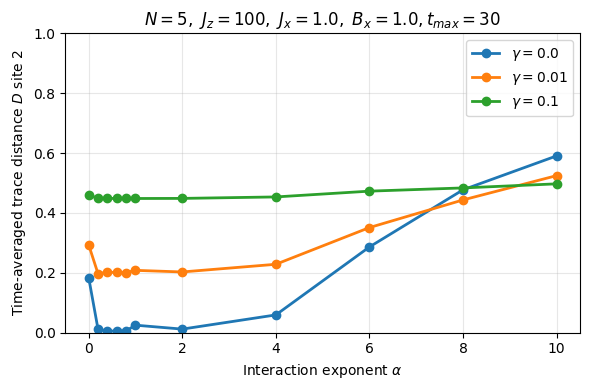

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import qutip as qt

# =========================
# Parameters
# =========================

N = 5
Jz = 100
Jx = 1.0
Bx = 1.0

gammas = [0.0, 0.01, 0.1] #
alphas = [i/5 for i in range(5)] + [1,2,4,6,8,10]

i0 = 2
tmax_cut = 30   # choose your physical observation window

plt.figure(figsize=(6,4))

# =========================
# Loop over gammas
# =========================

for gamma in gammas:

    D_avg_list = []

    for alpha in alphas:

        filename = (
            f"ED_Data/OpenMemory/LocalBitFlip/"
            f"RDM_site{i0}_vs_time_"
            f"N{N}_Jz{Jz}_Jx{Jx}_Bx{Bx}_"
            f"alpha{alpha}_gamma{gamma}.csv"
        )

        df = pd.read_csv(filename)

        # =========================
        # Reconstruct rho(t)
        # =========================

        times = df["time"].to_numpy()

        rho0 = qt.Qobj([
            [df["rho_00"].iloc[0], 
             df["rho_01_real"].iloc[0] + 1j*df["rho_01_imag"].iloc[0]],
            [df["rho_01_real"].iloc[0] - 1j*df["rho_01_imag"].iloc[0],
             df["rho_11"].iloc[0]]
        ])

        D_t = []

        for i in range(len(df)):

            rho_t = qt.Qobj([
                [df["rho_00"].iloc[i],
                 df["rho_01_real"].iloc[i] + 1j*df["rho_01_imag"].iloc[i]],
                [df["rho_01_real"].iloc[i] - 1j*df["rho_01_imag"].iloc[i],
                 df["rho_11"].iloc[i]]
            ])

            D_t.append(qt.tracedist(rho_t, rho0))

        D_t = np.array(D_t)

        # =========================
        # Time average
        # =========================

        

        mask = times <= tmax_cut

        D_avg = np.trapezoid(D_t[mask], times[mask]) / tmax_cut
        D_avg_list.append(D_avg)

    plt.plot(alphas, D_avg_list, marker='o', lw=2, label=fr"$\gamma={gamma}$")

# =========================
# Plot styling
# =========================

plt.xlabel(r"Interaction exponent $\alpha$")
plt.ylabel(rf"Time-averaged trace distance $D$ site {i0}")
plt.ylim(0,1)
plt.title(fr"Local decoherence at ")
plt.title(fr"$N={N},\ J_z={Jz},\ J_x={Jx},\ B_x={Bx}, t_{{max}}={tmax_cut}$")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.savefig("plt/LocalBitflip_tracedist_vs_alpha_Jz100.pdf")
plt.show()

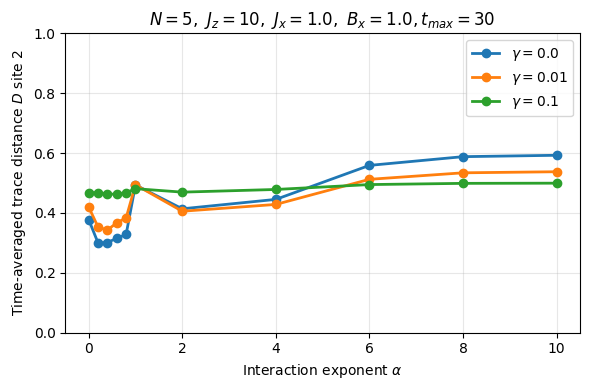

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import qutip as qt

# =========================
# Parameters
# =========================

N = 5
Jz = 10
Jx = 1.0
Bx = 1.0

gammas = [0.0, 0.01, 0.1] #
alphas = [i/5 for i in range(5)] + [1,2,4,6,8,10]

i0 = 2
tmax_cut = 30   # choose your physical observation window

plt.figure(figsize=(6,4))

# =========================
# Loop over gammas
# =========================

for gamma in gammas:

    D_avg_list = []

    for alpha in alphas:

        filename = (
            f"ED_Data/OpenMemory/LocalBitFlip/"
            f"RDM_site{i0}_vs_time_"
            f"N{N}_Jz{Jz}_Jx{Jx}_Bx{Bx}_"
            f"alpha{alpha}_gamma{gamma}.csv"
        )

        df = pd.read_csv(filename)

        # =========================
        # Reconstruct rho(t)
        # =========================

        times = df["time"].to_numpy()

        rho0 = qt.Qobj([
            [df["rho_00"].iloc[0], 
             df["rho_01_real"].iloc[0] + 1j*df["rho_01_imag"].iloc[0]],
            [df["rho_01_real"].iloc[0] - 1j*df["rho_01_imag"].iloc[0],
             df["rho_11"].iloc[0]]
        ])

        D_t = []

        for i in range(len(df)):

            rho_t = qt.Qobj([
                [df["rho_00"].iloc[i],
                 df["rho_01_real"].iloc[i] + 1j*df["rho_01_imag"].iloc[i]],
                [df["rho_01_real"].iloc[i] - 1j*df["rho_01_imag"].iloc[i],
                 df["rho_11"].iloc[i]]
            ])

            D_t.append(qt.tracedist(rho_t, rho0))

        D_t = np.array(D_t)

        # =========================
        # Time average
        # =========================

        

        mask = times <= tmax_cut

        D_avg = np.trapezoid(D_t[mask], times[mask]) / tmax_cut
        D_avg_list.append(D_avg)

    plt.plot(alphas, D_avg_list, marker='o', lw=2, label=fr"$\gamma={gamma}$")

# =========================
# Plot styling
# =========================

plt.xlabel(r"Interaction exponent $\alpha$")
plt.ylabel(rf"Time-averaged trace distance $D$ site {i0}")
plt.ylim(0,1)
plt.title(fr"Local decoherence at ")
plt.title(fr"$N={N},\ J_z={Jz},\ J_x={Jx},\ B_x={Bx}, t_{{max}}={tmax_cut}$")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.savefig("plt/LocalBitflip_tracedist_vs_alpha_Jz10.pdf")
plt.show()

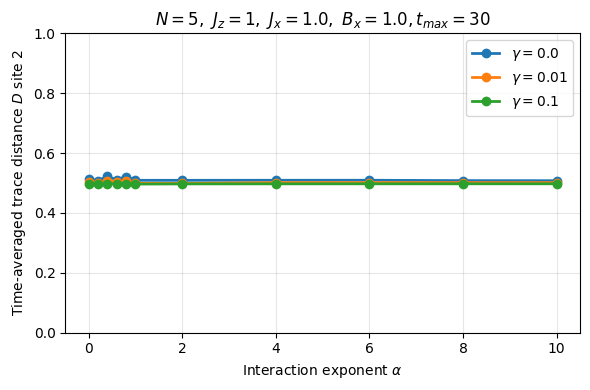

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import qutip as qt

# =========================
# Parameters
# =========================

N = 5
Jz = 1
Jx = 1.0
Bx = 1.0

gammas = [0.0, 0.01, 0.1] #
alphas = [i/5 for i in range(5)] + [1,2,4,6,8,10]

i0 = 2
tmax_cut = 30   # choose your physical observation window

plt.figure(figsize=(6,4))

# =========================
# Loop over gammas
# =========================

for gamma in gammas:

    D_avg_list = []

    for alpha in alphas:

        filename = (
            f"ED_Data/OpenMemory/LocalBitFlip/"
            f"RDM_site{i0}_vs_time_"
            f"N{N}_Jz{Jz}_Jx{Jx}_Bx{Bx}_"
            f"alpha{alpha}_gamma{gamma}.csv"
        )

        df = pd.read_csv(filename)

        # =========================
        # Reconstruct rho(t)
        # =========================

        times = df["time"].to_numpy()

        rho0 = qt.Qobj([
            [df["rho_00"].iloc[0], 
             df["rho_01_real"].iloc[0] + 1j*df["rho_01_imag"].iloc[0]],
            [df["rho_01_real"].iloc[0] - 1j*df["rho_01_imag"].iloc[0],
             df["rho_11"].iloc[0]]
        ])

        D_t = []

        for i in range(len(df)):

            rho_t = qt.Qobj([
                [df["rho_00"].iloc[i],
                 df["rho_01_real"].iloc[i] + 1j*df["rho_01_imag"].iloc[i]],
                [df["rho_01_real"].iloc[i] - 1j*df["rho_01_imag"].iloc[i],
                 df["rho_11"].iloc[i]]
            ])

            D_t.append(qt.tracedist(rho_t, rho0))

        D_t = np.array(D_t)

        # =========================
        # Time average
        # =========================

        

        mask = times <= tmax_cut

        D_avg = np.trapezoid(D_t[mask], times[mask]) / tmax_cut
        D_avg_list.append(D_avg)

    plt.plot(alphas, D_avg_list, marker='o', lw=2, label=fr"$\gamma={gamma}$")

# =========================
# Plot styling
# =========================

plt.xlabel(r"Interaction exponent $\alpha$")
plt.ylabel(rf"Time-averaged trace distance $D$ site {i0}")
plt.ylim(0,1)
plt.title(fr"Local decoherence at ")
plt.title(fr"$N={N},\ J_z={Jz},\ J_x={Jx},\ B_x={Bx}, t_{{max}}={tmax_cut}$")
plt.grid(alpha=0.3)
plt.legend()

plt.tight_layout()
plt.savefig("plt/LocalBitflip_tracedist_vs_alpha_Jz1.pdf")
plt.show()